In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


In [5]:
df = pd.read_csv("uber.csv")

# Remove unnecessary index/ID columns if present
df.drop(
    columns=["Unnamed: 0", "key"],
    errors="ignore",
    inplace=True
)

print("Original dataset shape:", df.shape)
print(df.head())
print("\nMissing values:\n", df.isnull().sum())

Original dataset shape: (200000, 7)
   fare_amount          pickup_datetime  pickup_longitude  pickup_latitude  \
0          7.5  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1          7.7  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2         12.9  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3          5.3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4         16.0  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         -73.965316         40.803349                3  
4         -73.973082         40.761247                5  

Missing values:
 fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitu

In [7]:
required = [
    "fare_amount",
    "pickup_datetime",
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "passenger_count"
]

missing_columns = set(required) - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")


In [9]:
# Convert date and time safely
df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce", utc=True
)

# Remove rows with missing required values
df.dropna(subset=required, inplace=True)

# Keep valid positive fares
df = df[df["fare_amount"] > 0].copy()

# Remove invalid coordinates outside the approximate NYC region
df = df[
    df["pickup_longitude"].between(-75, -72) &
    df["dropoff_longitude"].between(-75, -72) &
    df["pickup_latitude"].between(40, 42) &
    df["dropoff_latitude"].between(40, 42)
].copy()

# Valid passenger counts
df = df[df["passenger_count"].between(1, 6)].copy()

# Extract time features
df["pickup_hour"] = df["pickup_datetime"].dt.hour
df["pickup_day"] = df["pickup_datetime"].dt.dayofweek
df["pickup_month"] = df["pickup_datetime"].dt.month


In [11]:
def haversine(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(
        np.radians, [lon1, lat1, lon2, lat2]
    )

    dlon = lon2 - lon1
    dlat = lat2 - lat1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return 6371 * 2 * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine(
    df["pickup_longitude"],
    df["pickup_latitude"],
    df["dropoff_longitude"],
    df["dropoff_latitude"]
)

# Remove zero-distance and implausibly long trips
df = df[
    (df["distance_km"] > 0) &
    (df["distance_km"] <= 100)
].copy()

print("\nShape after basic cleaning:", df.shape)



Shape after basic cleaning: (193059, 11)


In [13]:
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = max(0, Q1 - 1.5 * IQR)
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["fare_amount"] < lower_bound) |
    (df["fare_amount"] > upper_bound)
]

print("\nFare outlier lower bound:", lower_bound)
print("Fare outlier upper bound:", upper_bound)
print("Number of fare outliers:", len(outliers))

# Exclude fare outliers for this comparison
df = df[
    df["fare_amount"].between(lower_bound, upper_bound)
].copy()

# Use a reproducible sample to reduce training time
if len(df) > 50000:
    df = df.sample(n=50000, random_state=42)

print("Shape after outlier removal and sampling:", df.shape)


Fare outlier lower bound: 0
Fare outlier upper bound: 22.25
Number of fare outliers: 16516
Shape after outlier removal and sampling: (50000, 11)



Correlation with fare_amount:
fare_amount          1.000000
distance_km          0.728669
dropoff_longitude    0.089234
pickup_month         0.028973
pickup_day           0.020434
passenger_count      0.015159
pickup_longitude     0.003021
pickup_hour         -0.011235
pickup_latitude     -0.084364
dropoff_latitude    -0.096973
Name: fare_amount, dtype: float64


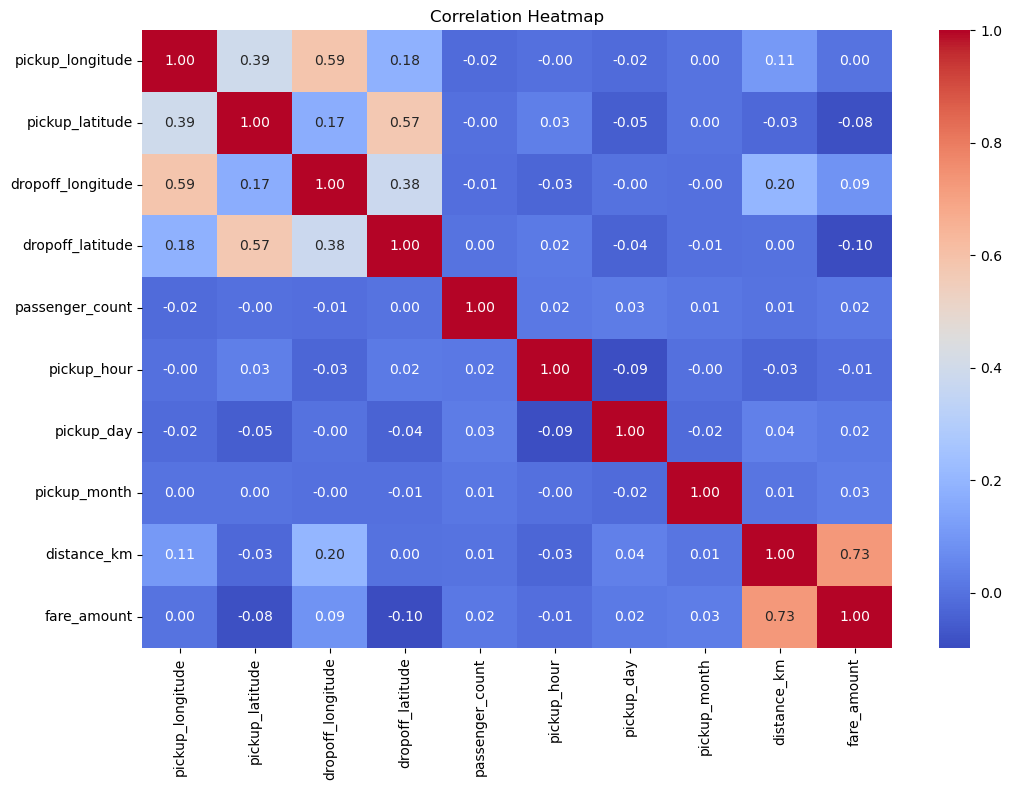

In [15]:
features = [
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "passenger_count",
    "pickup_hour",
    "pickup_day",
    "pickup_month",
    "distance_km"
]

target = "fare_amount"

correlation_data = df[features + [target]]
correlation = correlation_data.corr()

print("\nCorrelation with fare_amount:")
print(correlation[target].sort_values(ascending=False))

plt.figure(figsize=(11, 8))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


In [17]:
X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)


In [19]:
models = {
    "Linear Regression": make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),
    "Ridge Regression": make_pipeline(
        StandardScaler(),
        Ridge(alpha=1.0)
    ),
    "Lasso Regression": make_pipeline(
        StandardScaler(),
        Lasso(alpha=0.01, max_iter=10000)
    )
}

results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    results.append({
        "Model": name,
        "R2 Score": r2_score(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAE": mean_absolute_error(y_test, y_pred)
    })



Model Comparison:
            Model  R2 Score   RMSE    MAE
Linear Regression    0.5963 2.6375 1.8931
 Ridge Regression    0.5963 2.6376 1.8932
 Lasso Regression    0.5951 2.6414 1.8955

Lowest RMSE model: Linear Regression


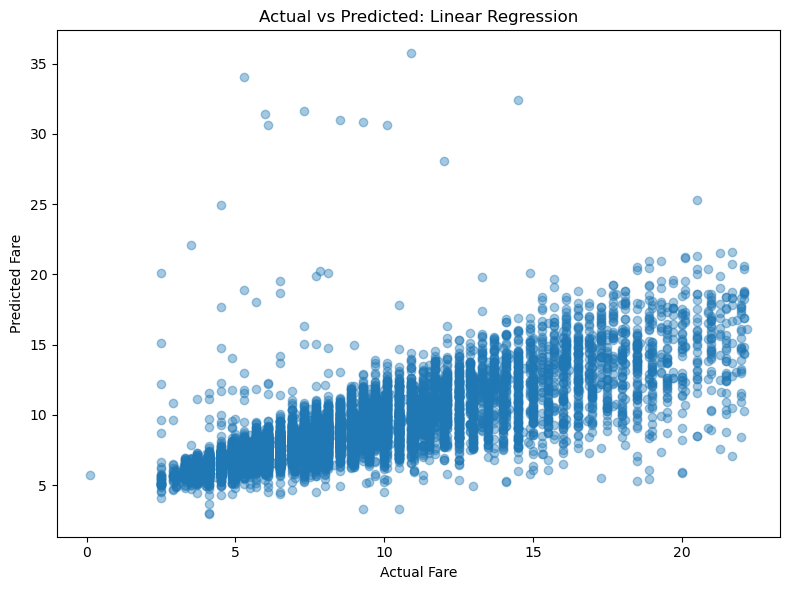

In [21]:
results_df = pd.DataFrame(results)

print("\nModel Comparison:")
print(results_df.round(4).to_string(index=False))

# Compare actual vs predicted fares
best_model_name = results_df.sort_values(
    "RMSE"
).iloc[0]["Model"]

print("\nLowest RMSE model:", best_model_name)

plt.figure(figsize=(8, 6))
plt.scatter(
    y_test,
    predictions[best_model_name],
    alpha=0.4
)
plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title(f"Actual vs Predicted: {best_model_name}")
plt.tight_layout()
plt.show()
